# SQLD 가이드 멀티모달 RAG — 실행 노트북

`src/`의 py 모듈을 3단계(추출 → 요약 → 검색·체인) 순서로 실행하고 결과를 남긴 노트북입니다. 위에서부터 차례로 실행합니다(Run All). 2·3단계는 OpenAI API를 호출합니다.

In [1]:
# 0. 준비 — 프로젝트 루트를 import 경로에 넣고 설정 확인
import pickle
import sys
from pathlib import Path

from IPython.display import Image, Markdown, display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())  # notebooks/ 에서 실행해도 프로젝트 루트를 찾음
sys.path.insert(0, str(PROJECT_ROOT))

from src import config

config.load_api_key()
print("구간:", ", ".join(f"{name} {start}~{end}쪽" for name, start, end in config.SECTIONS))
print("요약 모델:", config.LLM_MODEL, "| 답변 모델:", config.ANSWER_MODEL, "| 임베딩:", config.EMBEDDING_MODEL)


def largest_figure(page):
    """해당 쪽에서 추출한 그림 중 가장 큰 파일 (한 쪽에 그림이 여러 개면 본 그림을 고르기 위해)."""
    return max(config.FIGURES_DIR.glob(f"figure-p{page:03d}-*"), key=lambda f: f.stat().st_size)

API 키 로드 완료
구간: 관계·식별자 44~58쪽, 계층형 질의와 셀프 조인 324~337쪽
요약 모델: gpt-4o-mini | 답변 모델: gpt-4o-mini | 임베딩: text-embedding-3-small


In [2]:
# 1. 1단계 — 데이터 추출: 29쪽에서 텍스트·표·그림을 뽑고, 텍스트를 2,000토큰 단위로 다시 나눔 (약 2분)
from src import extract

extract.main()

PDF: sqld_guide_2020.pdf | 쪽 범위: [(44, 58), (324, 337)] | 추출할 쪽 29쪽


Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

추출 완료 — 136.6초 소요
  CompositeElement      : 19개
  Table                 : 12개
텍스트 블록: 19 | 표 블록: 12 | 그림: 28 개
분할 후 텍스트 블록: 23
제 장 데이터 모델링의 이해

제 절 관계 4 (Relationship)

1. 관계의 개념

가 관계의 정의

관계 (Relationship) 를 사전적으로 정의하면 상호 연관성이 있는 상태로 말할 수 있다 이 . 것을 데이터 모델에 대입하여 정의해 보면 엔터티의 인스턴스 사이의 논리적인 연관성으 , “ 로서 존재의 형태로서나 행위로서 서로에게 연관성이 부여된 상태 라고 할 수 있다 관계는 ” . 엔터티와 엔터티 간 연관성을 표현하기 때문에 엔터티의 정의에 따라 영향을 받기도 하고, 속성 정의 및 관계 정의에 따라서도 다양하게 변
저장 완료: C:\workspaces\multimodal-rag-sql\data\processed\extracted.pkl


텍스트 청크 23개 | 표 12개 | 그림 28개
그림 파일 예: figure-p044-1.jpg, figure-p045-2.jpg, figure-p045-3.jpg, figure-p046-4.jpg, figure-p047-5.jpg, figure-p047-6.jpg …
표 예시 (SYS_CONNECT_BY_PATH 실행 결과): 루트사원 경로 사원 관리자 ------- ------- ---- ----- A /A A A /A/B B A A /A/C C A A /A/C/D D C A /A/C/E E C


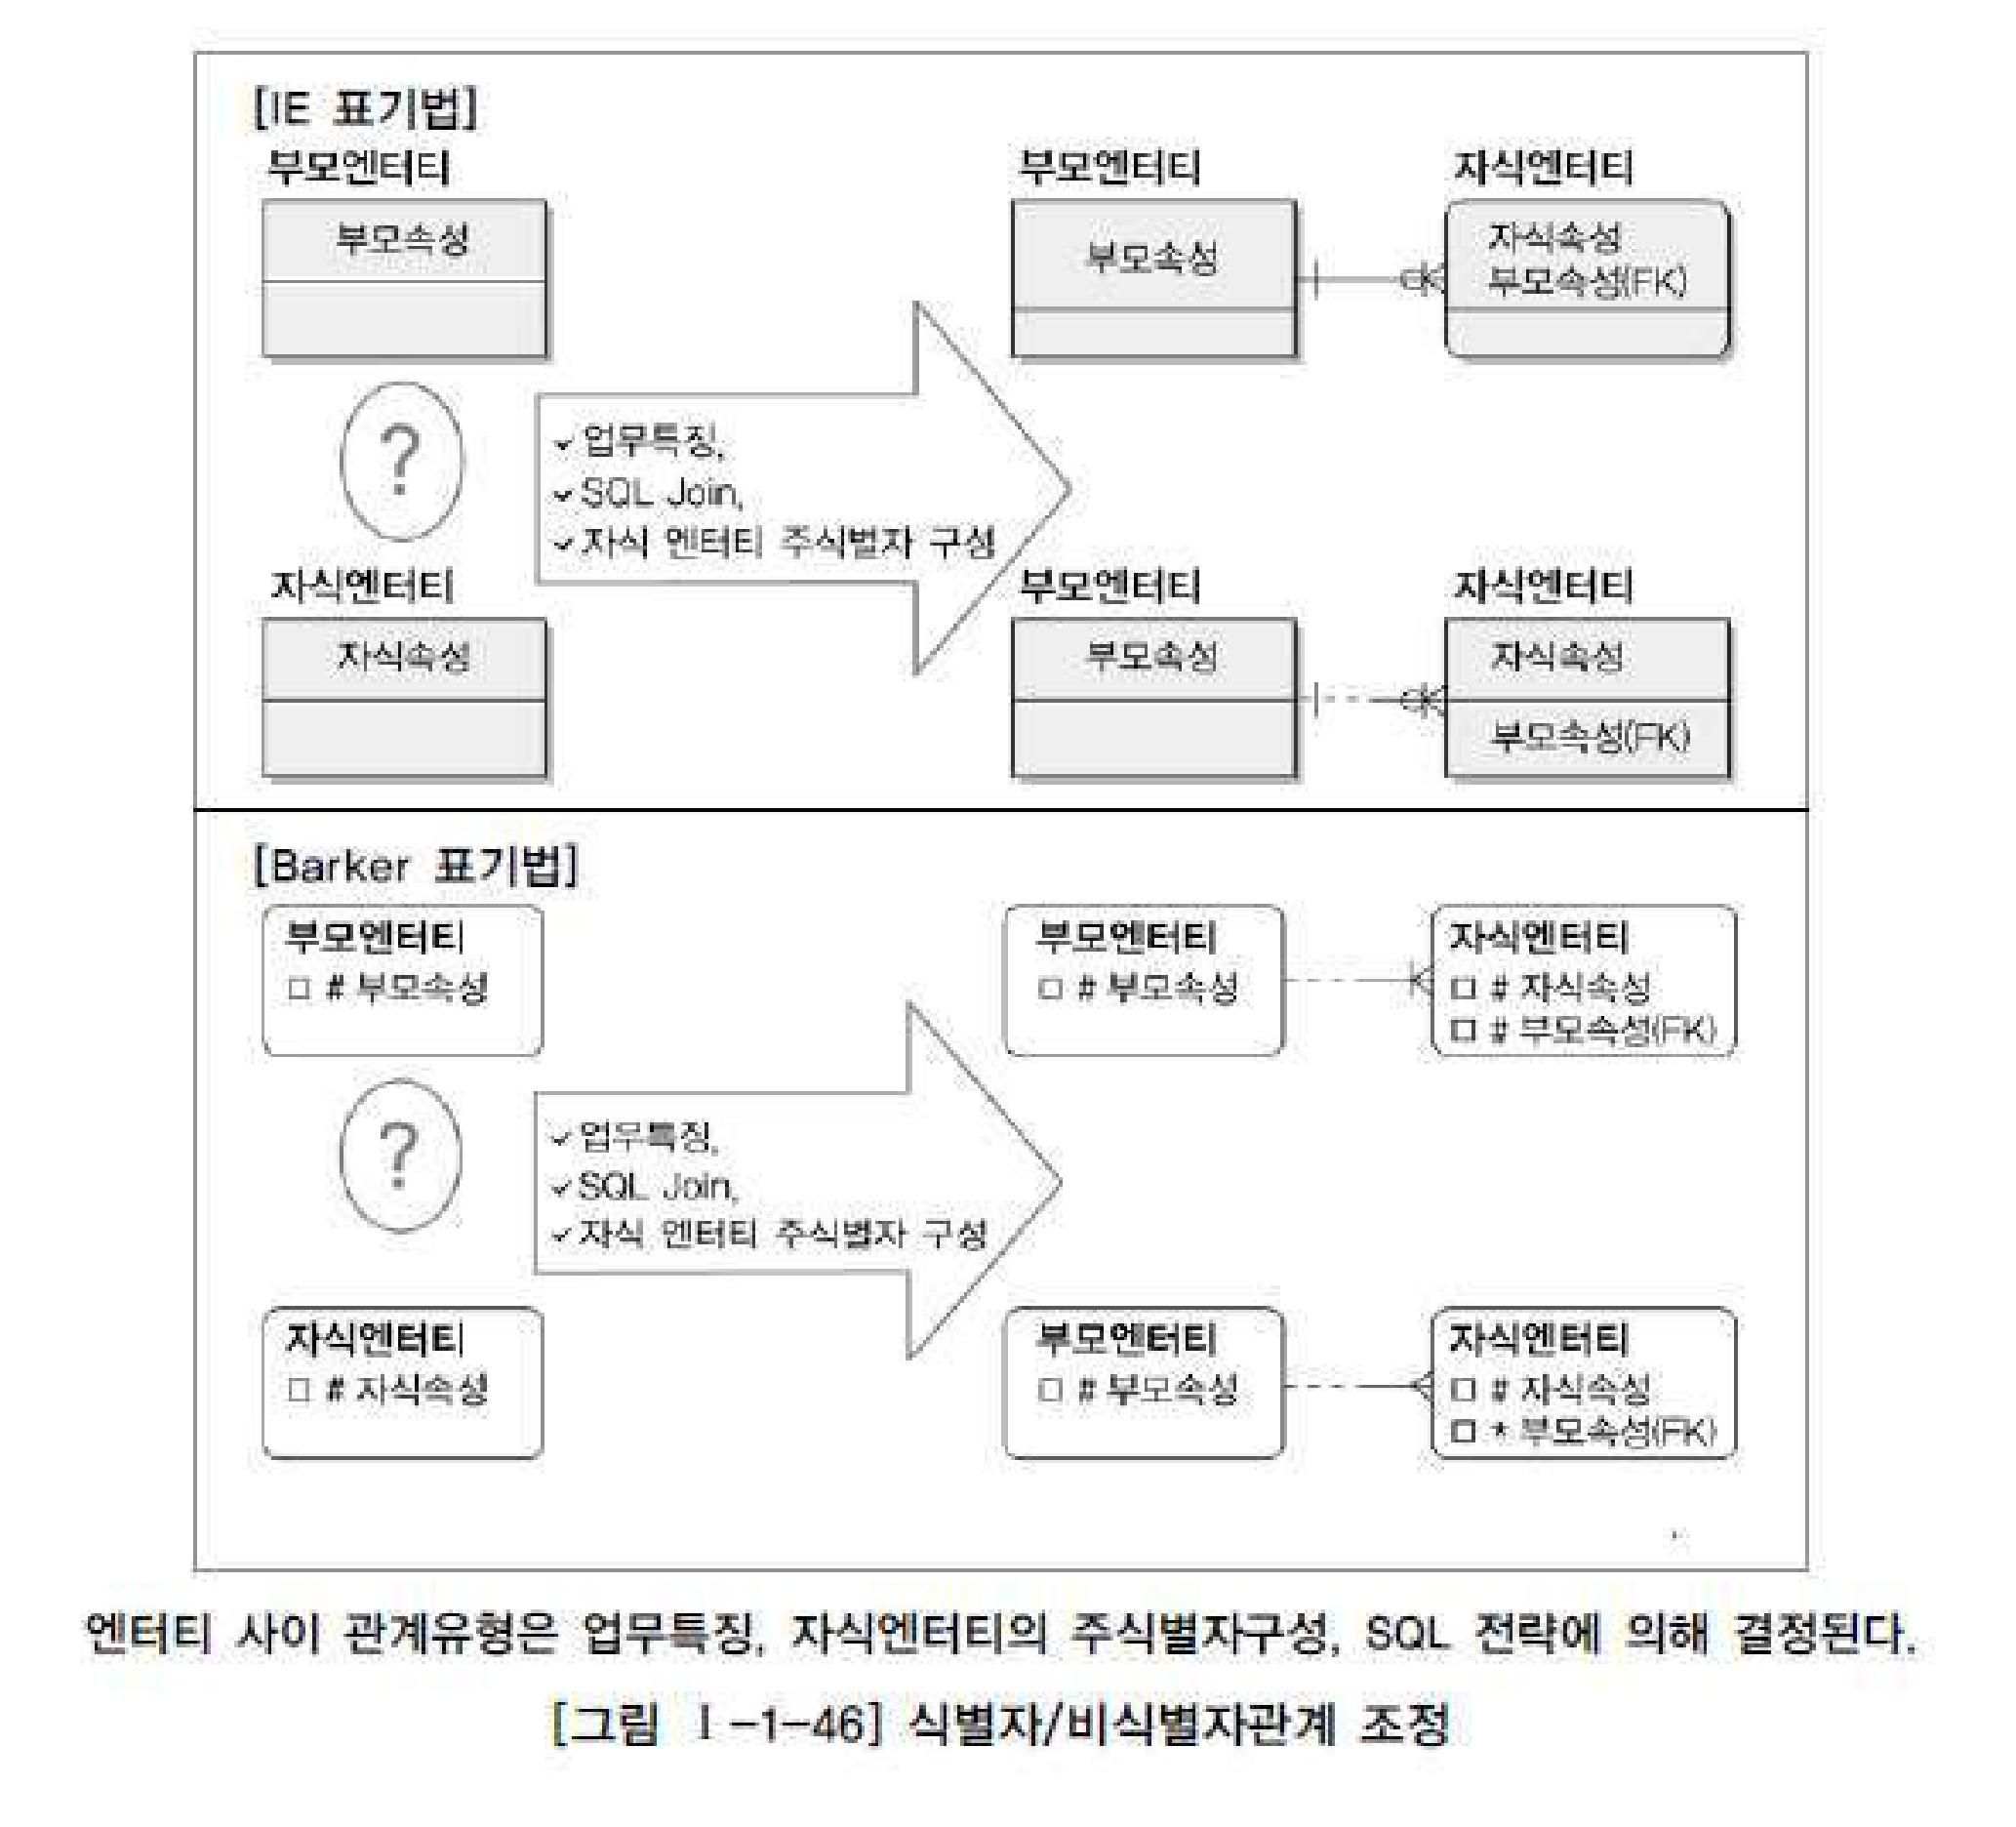

In [3]:
# 1-1. 추출 결과 확인 — 표 원문 예시와 data/figures/ 에 생긴 그림
with open(config.EXTRACTED_PKL, "rb") as f:
    extracted = pickle.load(f)

figures = sorted(config.FIGURES_DIR.glob("figure-*"))
print(f"텍스트 청크 {len(extracted['texts_2k_token'])}개 | 표 {len(extracted['tables'])}개 | 그림 {len(figures)}개")
print("그림 파일 예:", ", ".join(f.name for f in figures[:6]), "…")

path_table = next((t for t in extracted["tables"] if "/A/C/D" in t), extracted["tables"][0])  # 3번 질문의 근거가 되는 표
print("표 예시 (SYS_CONNECT_BY_PATH 실행 결과):", " ".join(path_table.split()))
display(Image(filename=str(largest_figure(58)), width=600))  # 1번 질문의 근거가 되는 그림 [그림 Ⅰ-1-46]

In [4]:
# 2. 2단계 — 요약 생성: 텍스트·표는 gpt-4o-mini, 그림은 gpt-4o-mini 비전으로 요약 (API 비용 발생)
from src import summarize

summarize.main()

API 키 로드 완료
원본 PDF: sqld_guide_2020.pdf | 쪽 범위: [(44, 58), (324, 337)]
텍스트·표 요약 완료 — 25.1초 | 텍스트 23건, 표 12건
압축률(첫 블록): 1099자 → 413자 (37.6%)
표 요약 예시: 이 표는 데이터베이스에서 계층적 쿼리를 수행할 때 사용되는 CONNECT BY 절의 기능을 설명합니다. 열 이름: 루트 데이터, 하위 데이터, LEVEL, CONNECT BY_ISLEAF, CONNECT BY_ISCYCLE 행 값: 681, 1, 1, 0, 0
추출 그림 28개 → 요약 대상 28개 (작은 그림 0개, 중복 0개 제외)
그림 요약 완료 — 16.2초 | 28장

[figure-p044-1.jpg]
[그림 I-1-30] 관계의 정의

- 강사 ↔ 가르친다 ↔ 수강생
- 인스턴스 사이의 논리적인 연관성으로서 존재 또는 행위로서 서로에게 연관성이 부여된 상태

[figure-p045-2.jpg]
그림 I-1-31 관계의 패어링

[IE 표기법] 
- 강사
- 수강생
- 관계: 강의한다

[Barker 표기법]
- 강사
- 수강생
- 관계: 강의한다

설명: 인스턴스 각각은 자신의 연관성을 가질 수 있으며, 이를 집합하여 '강의'라는 관계 도출.

[figure-p045-3.jpg]
존재에 의한 관계와 행위에 의한 관계를 나타내는 다이어그램. 

- 존재에 의한 관계:
  - 부서: DB팀
  - 사원: 환경빈
  - 관계: 소속하다
  - 설명: "사원에 부서에 항상 속해있다."

- 행위에 의한 관계:
  - 고객: 김경재
  - 주문: CTA201
  - 관계: 주문한다
  - 설명: "주문은 고객이 주문을 할 때 발생된다."

[그림 I-1-32] 관계의 분류

[figure-p046-4.jpg]
[그림 1-1-33] 관계의 관계명

- IE 표기법: 부서 포함한다, 사원 소속된다
- Barker 표기법: 부서 포함한다, 사원 소속된다

[figure-p047-5.jpg]
[IE 표

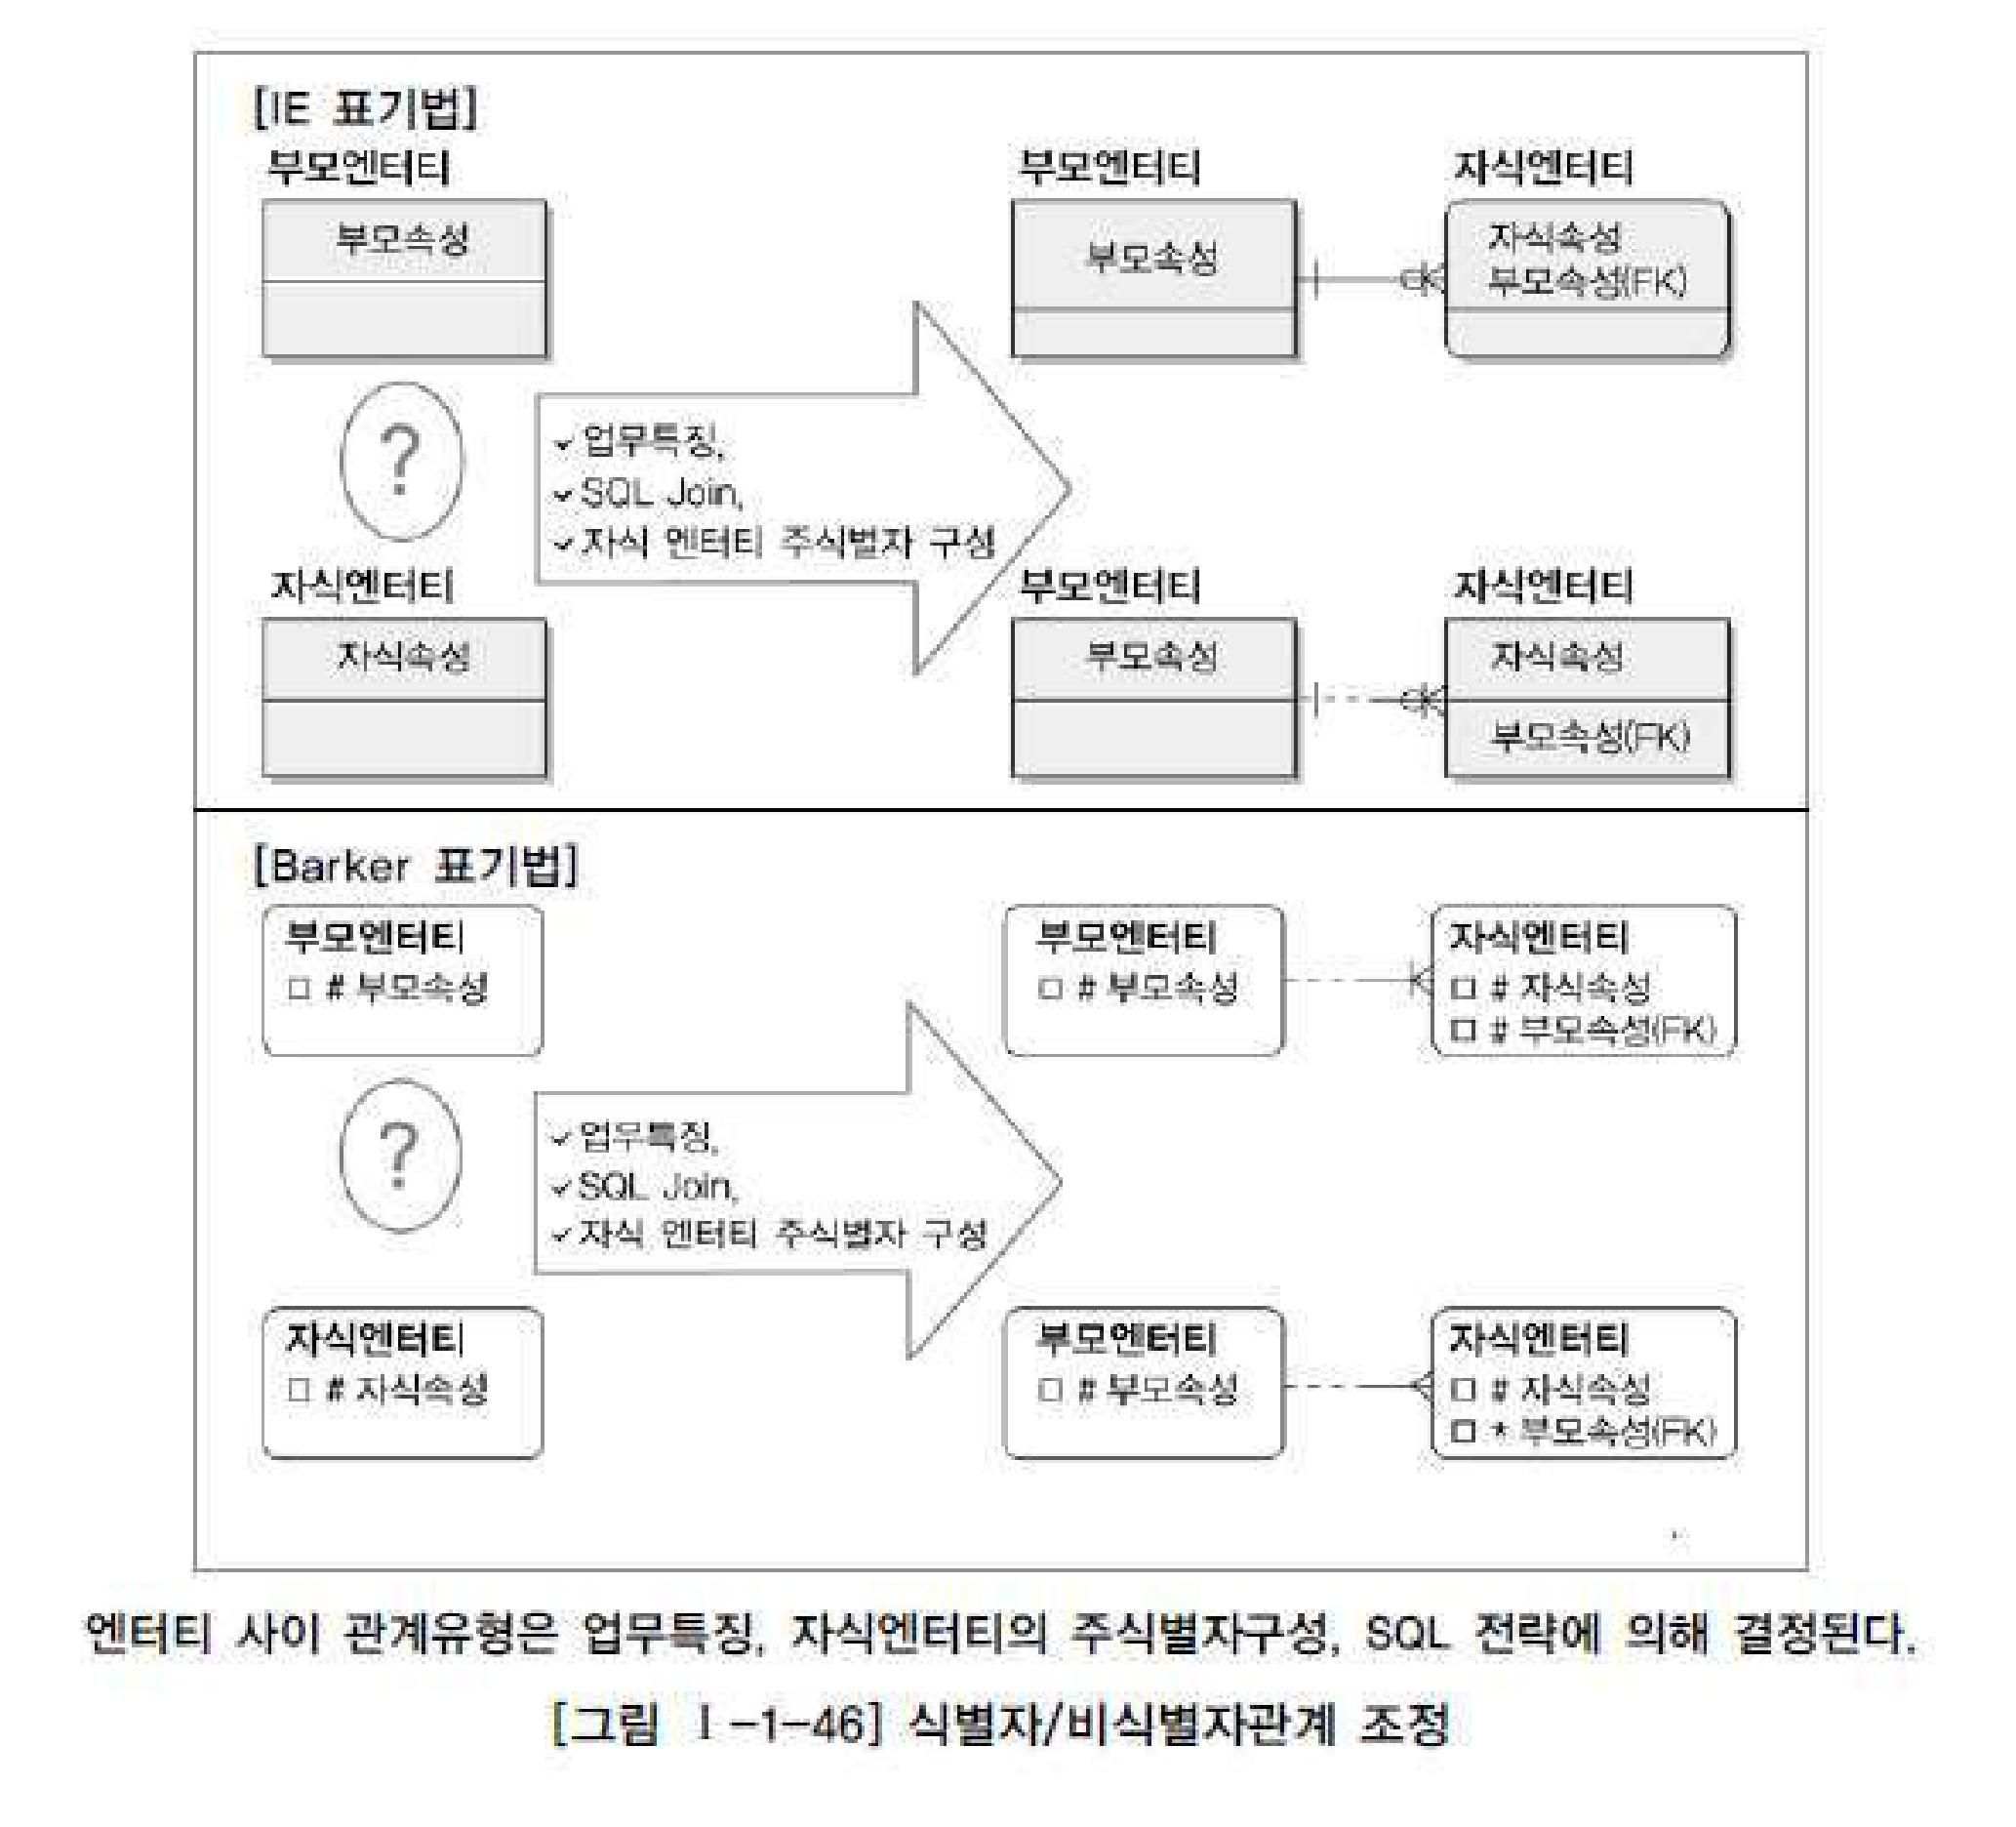

[figure-p058-20.jpg 요약] [IE 표기법] 부모엔터티, 자식엔터티, 업무특징, SQL Join, 자식 엔터티 주식별자 구성.  
[Barker 표기법] 부모엔터티, 자식엔터티, 업무특징, SQL Join, 자식 엔터티 주식별자 구성.  
부모엔터티와 자식엔터티 간의 관계를 나타내며, 자식엔터티의 속성은 부모엔터티의 외래키(FK)로 연결됨.  
엔터티 사이 관계유형은 업무특징, 자식엔터티의 주식별자구성, SQL 전략에 의해 결정됨.  
[그림 I-1-46] 식별자/비식별자관계 조정.



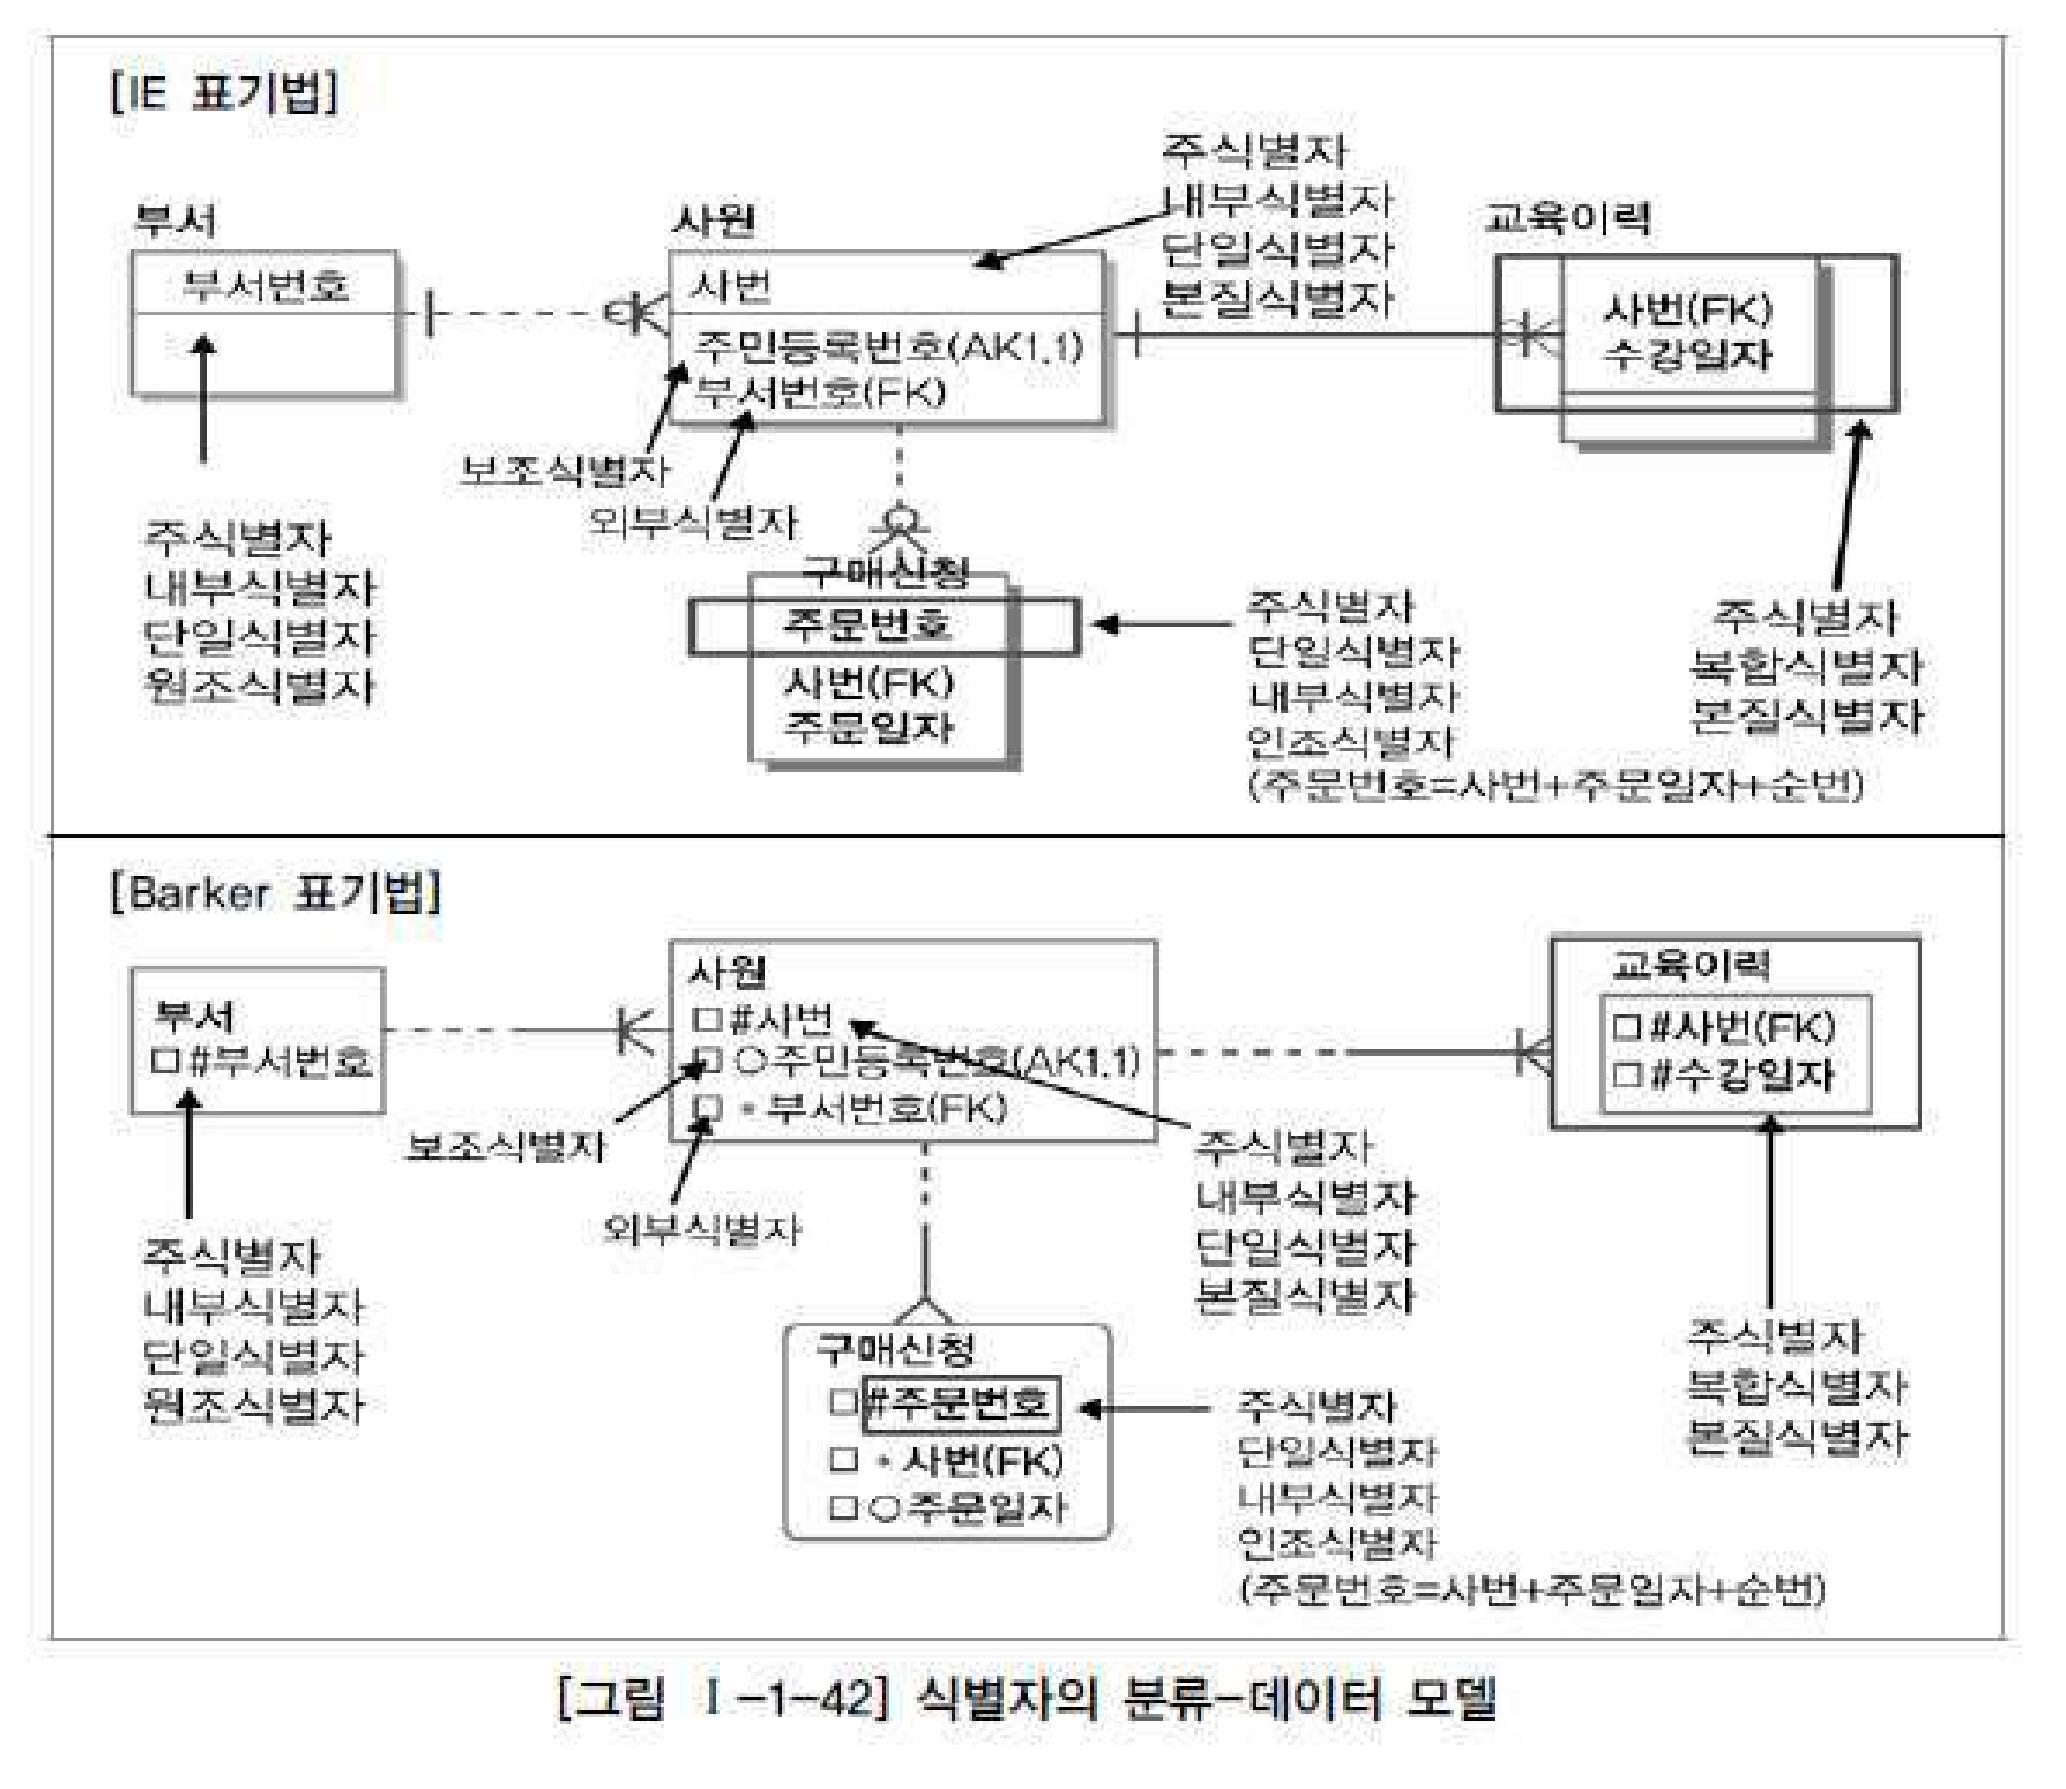

[figure-p054-15.jpg 요약] [그림 1-1-42] 식별자의 분류-데이터 모델

**IE 표기법:**
- 부서: 부서번호
- 사원: 주식별자, 내부식별자, 단일식별자, 분질식별자
- 교육이력: 사번(FK), 수강일자
- 구매신청: 주문번호, 사번(FK), 주문일자

**Barker 표기법:**
- 부서: #부서번호
- 사원: *사번(FK), ○주민등록번호(AK1,1), 부서번호(FK)
- 교육이력: #사번(FK), #강의일자
- 구매신청: #주문번호, 사번(FK), 주문일자

주요 관계 및 식별자 표기법이 포함된 데이터 모델.



In [5]:
# 2-1. 요약 품질 확인 — 평가 질문의 근거 그림과 요약문을 나란히 놓고 비교
with open(config.SUMMARIES_PKL, "rb") as f:
    summaries = pickle.load(f)

for page in [58, 54]:
    figure = largest_figure(page)
    display(Image(filename=str(figure), width=520))
    print(f"[{figure.name} 요약]", summaries["image_summaries"][summaries["image_names"].index(figure.name)])
    print()

In [6]:
# 3. 3단계 — 검색과 체인: 요약으로 검색해 원본을 꺼내는 다중 벡터 검색기, 원본(그림 포함)으로 답하는 멀티모달 체인, 비교용 텍스트 전용 체인
from src import evaluate

data, retriever, chain, text_only_chain = evaluate.build_all()

API 키 로드 완료
원본 PDF: sqld_guide_2020.pdf | 쪽 범위: [(44, 58), (324, 337)]
텍스트 원본  23건 / 요약  23건
테이블 원본  12건 / 요약  12건
이미지 원본  28건 / 요약  28건
색인 완료 — 벡터 DB에 저장된 요약 수: 63


In [7]:
# 3-1. 요약으로 찾고 원본을 받는다 — 같은 질문을 벡터 DB(요약)와 검색기(원본)에 던져 비교
question = config.EVAL_QUESTIONS[config.BEFORE_AFTER_INDEX]["question"]
print("질문:", question)

print("\n[벡터 DB가 찾은 요약 — 검색에 쓰는 것]")
for doc in retriever.vectorstore.similarity_search(question, k=config.RETRIEVER_K):
    print("  -", " ".join(doc.page_content.split())[:110])

print("\n[검색기가 돌려준 원본 — 답변에 쓰는 것]")
for e in evaluate.classify(retriever.invoke(question), data):
    print(f"  - [{e['type']}]", e["name"] if e["type"] == "이미지" else " ".join(e["text"].split())[:110])

질문: 식별자/비식별자 관계 조정 그림에 따르면, 엔터티 사이의 관계 유형은 무엇에 의해 결정되나요?

[벡터 DB가 찾은 요약 — 검색에 쓰는 것]
  - **요약: 데이터 모델링 및 식별자 개념** - **관계 정의 및 질문 기법**: 데이터 모델링에서 엔터티 간의 관계를 정의하기 위해 질문을 활용할 수 있다. 예를 들어, "하나의 주문에 대해 하나
  - [IE 표기법] 부모엔터티, 자식엔터티, 업무특징, SQL Join, 자식 엔터티 주식별자 구성. [Barker 표기법] 부모엔터티, 자식엔터티, 업무특징, SQL Join, 자식 엔터티 주식별자 
  - **식별자 정의 및 특징 요약** 1. **식별자 정의**: 엔터티 내에서 SIAR ASS를 구분하는 요소. 2. **주식별자 특징**: - 모든 인스턴스를 유일하게 구분해야 함. - 유일성을 만족
  - **요약: 선택참여관계 및 관계 정의** - **선택참여관계**: ERD에서 관계를 나타내는 선에서 선택참여하는 엔터티는 원으로 표시되며, 필수참여는 표시하지 않음. - **관계 검토**: 양쪽 엔

[검색기가 돌려준 원본 — 답변에 쓰는 것]
  - [텍스트] [le vida [Barker 표기법] 기 준 엔터티 관 련 엔터티 | 선 택 사양 Target) | 필 수 / 선 택 1 =o = ~ / 하 나의 !| (804006) 개 34 [그림 1-1-39
  - [이미지] figure-p058-20.jpg
  - [텍스트] Ry 식 별 자 는 엔 터 티 내 에 서 SIAR ASS 구분할 + 있는 바울 [그림 ｌ-1-40] 식 별 자 의 정의 2. 식별자의 특징 주식별자인지 아니면 외부식별자인지 등에 따라 특성이 다소 
  - [텍스트] 선택참여관계는 ERD 에서 관계를 나타내는 선에서 선택참여하는 엔터티 쪽을 원으로 표 시한다 필수참여는 아무런 표시를 하지 않는다 . . 만약 관계가 표시된 양쪽 엔터티에 모두 선택참여가 표시된다면


In [8]:
# 3-2. 평가 — 질문 5개를 텍스트 전용 RAG와 멀티모달 RAG에 모두 던짐 (API 호출 10번)
report = evaluate.run(data, retriever, chain, text_only_chain)

1/5 완료 — 근거 이미지 1 (figure-p058-20.jpg) · 텍스트 3
2/5 완료 — 근거 이미지 3 (figure-p054-14.jpg, figure-p053-13.jpg, figure-p053-12.jpg) · 텍스트 1
3/5 완료 — 근거 이미지 1 (figure-p328-26.jpg) · 표 1 · 텍스트 2
4/5 완료 — 근거 이미지 1 (figure-p328-26.jpg) · 표 2 · 텍스트 1
5/5 완료 — 근거 이미지 2 (figure-p325-22.jpg, figure-p328-26.jpg) · 표 1 · 텍스트 1


In [9]:
# 3-3. Before / After — 이 셀의 출력을 캡처해서 docs/before_after.png 로 저장 (README에 들어감)
print(report["headline"])

질문: 식별자/비식별자 관계 조정 그림에 따르면, 엔터티 사이의 관계 유형은 무엇에 의해 결정되나요?
[BEFORE] 텍스트 전용 RAG
자료에 따르면, 엔터티 사이의 관계 유형은 업무 분석을 통해 결정됩니다. 관계를 정의하기 위해서는 두 개의 엔터티 사이에 관심 있는 연관 규칙이 존재하는지, 정보의 조합이 발생되는지, 그리고 업무 기술서에 관계 연결에 대한 규칙이나 동사가 서술되어 있는지를 체크해야 합니다. 이러한 질문을 통해 관계를 도출할 수 있습니다.

[AFTER] 멀티모달 RAG (검색 근거: 이미지 1 (figure-p058-20.jpg) · 텍스트 3)
엔터티 사이의 관계 유형은 업무특징, 자식 엔터티의 주식별자 구성, SQL 전략에 의해 결정됩니다.


In [10]:
# 3-4. 질의응답 5건 — 질문 / 답변 / 근거가 된 원본 종류 (docs/qa_table.md)
display(Markdown(report["qa_table"]))

| # | 질문 | 답변 | 근거가 된 원본 종류 |
|---|---|---|---|
| 1 | 식별자/비식별자 관계 조정 그림에 따르면, 엔터티 사이의 관계 유형은 무엇에 의해 결정되나요? | 엔터티 사이의 관계 유형은 업무특징, 자식 엔터티의 주식별자 구성, SQL 전략에 의해 결정됩니다. | 이미지 1 (figure-p058-20.jpg) · 텍스트 3 |
| 2 | 식별자의 분류 그림에서 교육이력 엔터티의 주식별자는 어떤 속성들로 구성되고, 어떤 식별자로 분류되나요? | 교육이력 엔터티의 주식별자는 "주식별자"로 분류되며, 다음과 같은 속성들로 구성됩니다: 1. **유일성**: 주식별자에 의해 엔터티 내의 모든 인스턴스들이 유일하게 구분되어야 합니다. 2. **최소성**: 주식별자를 구성하는 속성의 수는 유일성을 만족하는 최소의 수가 되어야 합니다. 3. **불변성**: 지정된 주식별자의 값은 자주 변하지 않아야 합니다. 4. **존재성**: 주식별자가 지정되면 반드시 값이 들어와야 합니다. 이러한 속성들은 주식별자의 특성에 해당합니다. | 이미지 3 (figure-p054-14.jpg, figure-p053-13.jpg, figure-p053-12.jpg) · 텍스트 1 |
| 3 | SYS_CONNECT_BY_PATH 함수 예제의 실행 결과에서 사원 D의 경로는 무엇인가요? | 사원 D의 경로는 "A/C/D"입니다. | 이미지 1 (figure-p328-26.jpg) · 표 1 · 텍스트 2 |
| 4 | 계층형 질의에서 CONNECT_BY_ROOT는 무엇을 표시하고, 어떤 종류의 연산자인가요? | CONNECT_BY_ROOT는 현재 전개할 데이터의 루트 데이터를 표시하는 단항 연산자입니다. 이 함수는 계층형 질의에서 루트 데이터부터 현재 전개할 데이터까지의 경로를 나타냅니다. | 이미지 1 (figure-p328-26.jpg) · 표 2 · 텍스트 1 |
| 5 | 계층형 질의에서 START WITH절과 CONNECT BY절은 각각 무엇을 지정하나요? | 계층형 질의에서 `START WITH` 절은 계층 구조의 시작점을 지정하며, `CONNECT BY` 절은 부모와 자식 간의 관계를 정의하여 계층 구조를 탐색하는 데 사용됩니다. `START WITH` 절에 의해 지정된 조건을 만족하는 데이터가 루트 노드가 되고, `CONNECT BY` 절에 의해 정의된 조건에 따라 하위 데이터가 연결됩니다. | 이미지 2 (figure-p325-22.jpg, figure-p328-26.jpg) · 표 1 · 텍스트 1 |

In [11]:
# 3-5. 두 결과 비교 — 텍스트 전용 vs 멀티모달, 근거 종류별·구간별 (docs/comparison.md)
display(Markdown(report["comparison"]))

#### 질문별 채점 (정답 키워드 기준, 번호는 질의응답 표와 같음)

| # | 구간 | 정답 근거 | 정답 키워드 | 근거 검색 | Before 텍스트 전용 | After 멀티모달 |
|---|---|---|---|---|---|---|
| 1 | 관계·식별자 | 이미지 (58쪽) | 업무, 특징, 주식별자, SQL | 적중 | 부분 (1/4) | 정답 (4/4) |
| 2 | 관계·식별자 | 이미지 (54쪽) | 수강일자, 복합식별자 | 적중 | 모름 (0/2) | 오답 (0/2) |
| 3 | 계층형 질의와 셀프 조인 | 표 (328쪽) | /A/C/D | 빗나감 | 오답 (0/1) | 오답 (0/1) |
| 4 | 계층형 질의와 셀프 조인 | 표 (328쪽) | 루트, 단항 | 적중 | 부분 (1/2) | 정답 (2/2) |
| 5 | 계층형 질의와 셀프 조인 | 텍스트 (325쪽) | 시작, 루트, 자식 | 빗나감 | 정답 (3/3) | 정답 (3/3) |

#### 근거 종류별 요약

| 근거 종류 | 문항 | 근거 검색 | Before 정답 (키워드) | After 정답 (키워드) |
|---|---|---|---|---|
| 이미지 | 2 | 2/2 | 0/2 (1/6) | 1/2 (4/6) |
| 표 | 2 | 1/2 | 0/2 (1/3) | 1/2 (2/3) |
| 텍스트 | 1 | 0/1 | 1/1 (3/3) | 1/1 (3/3) |
| 전체 | 5 | 3/5 | 1/5 (5/12) | 3/5 (9/12) |

#### 구간별 요약

| 구간 | 문항 | 근거 검색 | Before 정답 (키워드) | After 정답 (키워드) |
|---|---|---|---|---|
| 관계·식별자 (44~58쪽) | 2 | 2/2 | 0/2 (1/6) | 1/2 (4/6) |
| 계층형 질의와 셀프 조인 (324~337쪽) | 3 | 1/3 | 1/3 (4/6) | 2/3 (5/6) |
| 전체 | 5 | 3/5 | 1/5 (5/12) | 3/5 (9/12) |

#### 해석 (규칙으로 자동 생성)

- 전체 5문항 중 텍스트 전용 RAG는 1문항, 멀티모달 RAG는 3문항을 맞혔습니다 (차이 +2, 정답 키워드 포함 5/12 → 9/12).
- 근거가 이미지인 문항: 텍스트 전용 0/2, 멀티모달 1/2.
- 근거가 표인 문항: 텍스트 전용 0/2, 멀티모달 1/2.
- 근거가 텍스트인 문항: 텍스트 전용 1/1, 멀티모달 1/1.
- 텍스트 전용 RAG가 '모른다'고 답한 문항: [2] — 텍스트 검색으로는 근거를 찾지 못했습니다.
- 정답 근거를 검색하지 못한 문항: [3, 5] — 질문 표현이나 요약 프롬프트를 점검해야 합니다.
- 정답 근거를 찾고도 멀티모달 답이 정답이 아닌 문항: [2] — 원본 판독 문제이거나 답이 정답 키워드와 다른 표현을 썼을 수 있습니다. docs/eval_results.json 의 답변을 직접 확인하세요.